# Aufgabe 7


In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import butter, sosfiltfilt

Abtastfrequenz: 103.12237122074322 Hz
Standardabweichung: 0.0006649378234496504 s


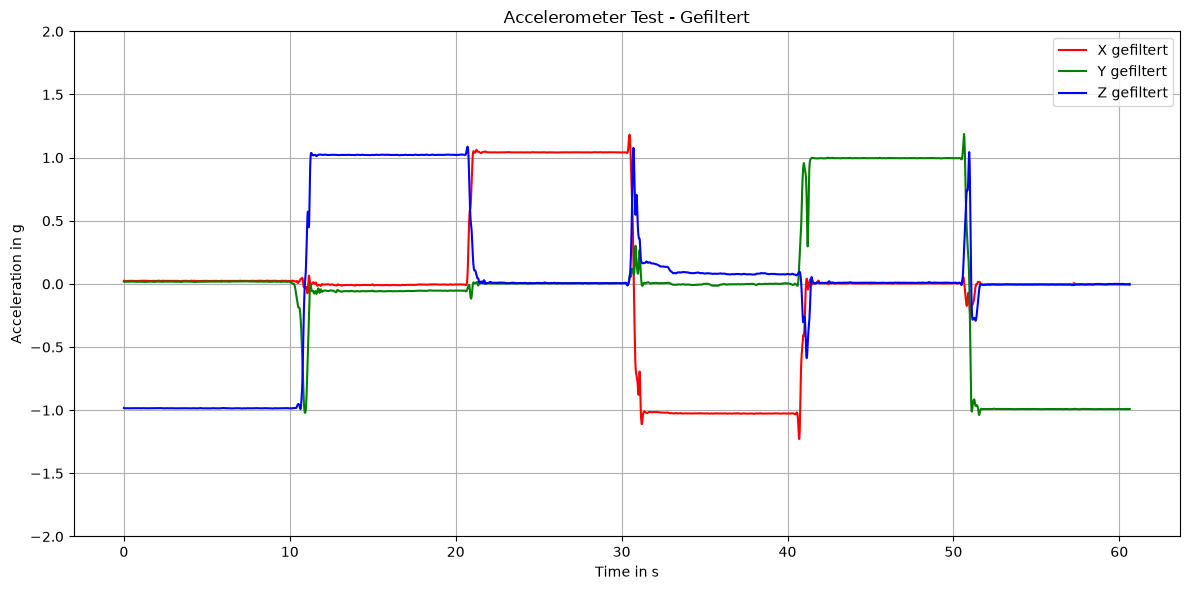

In [30]:
# CSV-Datei einlesen
df = pd.read_csv(
    r"source/achsen.csv",
    sep="\t",
    header=None,
    names=["Time", "X", "Y", "Z"]
)

# Zeit von Millisekunden in Sekunden umrechnen
df["Time"] = (df["Time"] - df["Time"].iloc[0]) / 1000

# Beschleunigung in g umrechnen
df["X"] = df["X"] / 1024
df["Y"] = df["Y"] / 1024
df["Z"] = df["Z"] / 1024

# Abtastfrequenz berechnen (Aufgabe 8)
dt = df["Time"].diff().dropna()
fs = 1 / dt.mean()

print("Abtastfrequenz:", fs, "Hz")
print("Standardabweichung:", dt.std(), "s")

# Butterworth-Tiefpassfilter anwenden
cutoff = 5
sos = butter(2, cutoff, btype="lowpass", fs=fs, output="sos")

for axis in ["X", "Y", "Z"]:
    df[axis + "_filtered"] = sosfiltfilt(sos, df[axis])

# Alle drei Achsen in einem Diagramm darstellen
plt.figure(figsize=(12, 6))

for axis, color in zip(["X", "Y", "Z"], ["red", "green", "blue"]):
    plt.plot(df["Time"], df[axis + "_filtered"],
             color=color, label=axis + " gefiltert")

plt.title("Accelerometer Test - Gefiltert")
plt.xlabel("Time in s")
plt.ylabel("Acceleration in g")

plt.ylim(-2, 2)
plt.legend()
plt.grid()
plt.tight_layout()
#plt.savefig("Aufgabe_7_Abbildung.png", dpi=300)
plt.show()
